# **Assignment 08**

---

## **Import External Libraries**

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from IPython.display import display, Math

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

---

## **1. No-Cloning Theorem**

In [2]:
# --- Problem 1: cloning by linearity vs. cloning by definition ---
def latex_matrix(M):
    """LaTeX for a numeric array: rounded to 4 d.p., whole numbers shown as integers."""
    M = np.round(np.real_if_close(np.asarray(M, dtype=complex)), 4) + 0.0
    return sp.latex(sp.Matrix(M).applyfunc(lambda v: sp.Integer(int(v)) if float(v).is_integer() else v))


I2 = np.eye(2)
X  = np.array([[0, 1], [1, 0]])
Z  = np.array([[1, 0], [0, -1]])
H  = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]])   # |0><0|
P1 = np.array([[0, 0], [0, 1]])   # |1><1|

ket0, ket1 = np.array([1, 0]), np.array([0, 1])
plus, minus = (ket0 + ket1) / np.sqrt(2), (ket0 - ket1) / np.sqrt(2)

# Symbolic check with |a> = |0>, |b> = |1> (orthonormal, so |aa>, |ab>, |ba>, |bb> are independent)
aa, ab, ba, bb = sp.symbols("aa ab ba bb")   # stand-ins for the four product kets
by_definition = sp.expand(sp.Rational(1, 2) * (aa + ab + ba + bb))
by_linearity  = (aa + bb) / sp.sqrt(2)
display(Math(r"\text{definition: } " + sp.latex(by_definition)))
display(Math(r"\text{linearity: } " + sp.latex(by_linearity)))
print("Problem 1  --  coefficient of |ab>:  definition", by_definition.coeff(ab), "  linearity", by_linearity.coeff(ab))

print("---------------")

# A concrete candidate cloner: CNOT (A controls, B is the target) copies |0> and |1> ...
CNOT = np.kron(P0, I2) + np.kron(P1, X)
print("Problem 1  --  CNOT|0>|0> == |0>|0> ?", np.allclose(CNOT @ np.kron(ket0, ket0), np.kron(ket0, ket0)))
print("Problem 1  --  CNOT|1>|0> == |1>|1> ?", np.allclose(CNOT @ np.kron(ket1, ket0), np.kron(ket1, ket1)))
# ... but not their superposition |+>: it gives (|00> + |11>)/sqrt2, not |+>|+>
out = CNOT @ np.kron(plus, ket0)
display(Math(r"\text{CNOT}\ket{+}\ket{0} = " + latex_matrix(out.reshape(1, -1))
             + r",\quad \ket{+}\ket{+} = " + latex_matrix(np.kron(plus, plus).reshape(1, -1))))
print("Problem 1  --  CNOT|+>|0> == |+>|+> ?", np.allclose(out, np.kron(plus, plus)))

print("---------------")

# Unitarity: L preserves inner products, so <a|b> = <a|b>^2 for any two clonable states
s = sp.symbols("s")
print("Problem 1  --  solutions of <a|b> = <a|b>^2 :", sp.solve(sp.Eq(s, s**2), s))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 1  --  coefficient of |ab>:  definition 1/2   linearity 0
---------------
Problem 1  --  CNOT|0>|0> == |0>|0> ? True
Problem 1  --  CNOT|1>|0> == |1>|1> ? True


<IPython.core.display.Math object>

Problem 1  --  CNOT|+>|0> == |+>|+> ? False
---------------
Problem 1  --  solutions of <a|b> = <a|b>^2 : [0, 1]


---

## **2. Quantum Teleportation of a Superposition State**

In [3]:
# --- Problem 2: the simplified teleportation circuit of Figure 1 (q1 = Alice = MSB, q0 = Bob = LSB) ---
H_M  = np.kron(H, I2)          # H on Alice (MSB is the first tensor factor)
M_2b = H_M @ CNOT @ H_M        # gates in time order H, CNOT, H  ->  product with the first gate on the right
display(Math(r"(H \otimes I)\,\text{CNOT}\,(H \otimes I) = " + latex_matrix(M_2b)))
print("Problem 2  --  equals 1/2 [[1,1,1,-1],[1,1,-1,1],[1,-1,1,1],[-1,1,1,1]] ?",
      np.allclose(2 * M_2b, [[1, 1, 1, -1], [1, 1, -1, 1], [1, -1, 1, 1], [-1, 1, 1, 1]]))
print("Problem 2  --  the two H's cancel (product == CNOT) ?", np.allclose(M_2b, CNOT))

state = M_2b @ np.kron(ket0, ket0)
display(Math(r"(H \otimes I)\,\text{CNOT}\,(H \otimes I)\ket{00} = " + latex_matrix(state.reshape(1, -1))))
print("Problem 2  --  state == (|0>|+> + |1>|->)/sqrt2 ?",
      np.allclose(state, (np.kron(ket0, plus) + np.kron(ket1, minus)) / np.sqrt(2)))
print("Problem 2  --  after Alice's H, Alice's qubit is |+> ?", np.allclose(H @ ket0, plus))

<IPython.core.display.Math object>

Problem 2  --  equals 1/2 [[1,1,1,-1],[1,1,-1,1],[1,-1,1,1],[-1,1,1,1]] ? True
Problem 2  --  the two H's cancel (product == CNOT) ? False


<IPython.core.display.Math object>

Problem 2  --  state == (|0>|+> + |1>|->)/sqrt2 ? True
Problem 2  --  after Alice's H, Alice's qubit is |+> ? True


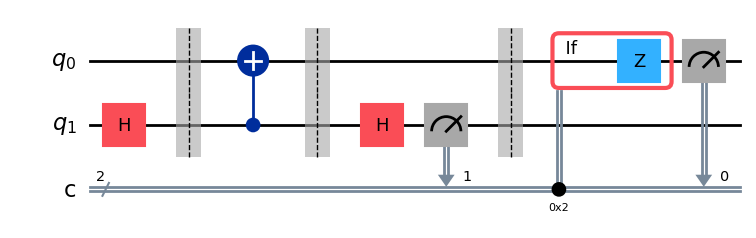

Figure 1  (bit string c1 c0 = Alice, Bob)
  00:   251 / 1024
  01:   253 / 1024
  10:   263 / 1024
  11:   257 / 1024
Figure 1 + H on Bob (verify)  (bit string c1 c0 = Alice, Bob)
  00:   504 / 1024
  01:     0 / 1024
  10:   520 / 1024
  11:     0 / 1024
verify, but without the Z gate  (bit string c1 c0 = Alice, Bob)
  00:   521 / 1024
  01:     0 / 1024
  10:     0 / 1024
  11:   503 / 1024


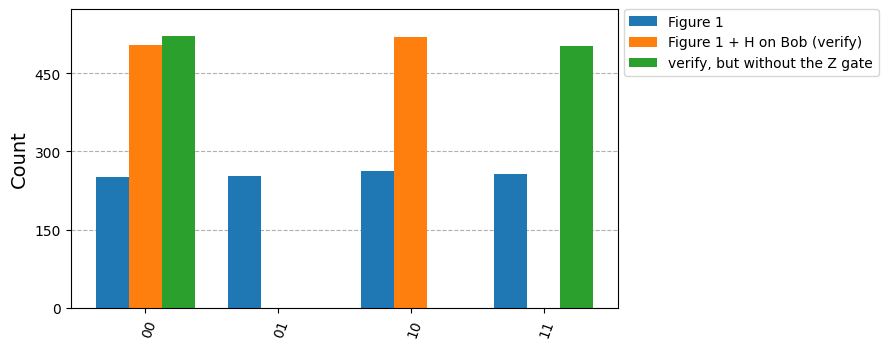

In [4]:
# --- Problem 2: simulate Figure 1 (and a check that Bob really holds |+>) ---
SHOTS = 1024
sim = AerSimulator(seed_simulator=2110515)


def figure1(verify=False, correct=True):
    """Figure 1. verify: H on Bob before his measurement (|+> -> |0>). correct: keep the conditional Z."""
    c  = ClassicalRegister(2, "c")
    qc = QuantumCircuit(QuantumRegister(2, "q"), c)
    qc.h(1)                       # prepare Alice's state |+>
    qc.barrier()
    qc.cx(1, 0)                   # Step 1: entangle Alice (control) with Bob
    qc.barrier()
    qc.h(1)                       # Step 2: measure Alice in the |+>/|-> basis
    qc.measure(1, 1)
    qc.barrier()
    if correct:
        with qc.if_test((c, 2)):  # Step 3: Bob applies Z if c == (10)_2
            qc.z(0)
    if verify:
        qc.h(0)
    qc.measure(0, 0)
    return qc


def counts(qc):
    return sim.run(qc, shots=SHOTS).result().get_counts()


def report(cnt, label, nbits):
    print(label)
    for k in range(2 ** nbits):
        key = format(k, f"0{nbits}b")
        print(f"  {key}:  {cnt.get(key, 0):4d} / {SHOTS}")


qc = figure1()
display(qc.draw("mpl"))
plt.close("all")

runs = {
    "Figure 1":                          counts(figure1()),
    "Figure 1 + H on Bob (verify)":      counts(figure1(verify=True)),
    "verify, but without the Z gate":    counts(figure1(verify=True, correct=False)),
}
for label, cnt in runs.items():
    report(cnt, label + "  (bit string c1 c0 = Alice, Bob)", 2)

fig = plot_histogram(list(runs.values()), legend=list(runs), figsize=(9, 3.6), bar_labels=False)
fig.savefig("../images/problem-2-answer.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

---

## **3. No-Cloning Theorem and Heisenberg Uncertainty Principle**

In [5]:
# --- Problem 3: a cloner made for one basis fails in the other ---
# CNOT clones the Z basis {|0>, |1>}; the cloner for the X basis {|+>, |->} is (H(x)H) CNOT (H(x)H)
HH = np.kron(H, H)
CNOT_X = HH @ CNOT @ HH
for name, L in (("Z-basis cloner", CNOT), ("X-basis cloner", CNOT_X)):
    for kname, k in (("|0>", ket0), ("|1>", ket1), ("|+>", plus), ("|->", minus)):
        out = L @ np.kron(k, ket0 if L is CNOT else plus)   # blank state: |0> for Z, |+> for X
        print(f"Problem 3  --  {name} on {kname}:  clone succeeds? {np.allclose(out, np.kron(k, k))}")
    print("---------------")

# |<0|+>|^2 = 1/2: a state definite in Z is maximally uncertain in X
print("Problem 3  --  |<0|+>|^2 =", round(abs(ket0 @ plus) ** 2, 4))

Problem 3  --  Z-basis cloner on |0>:  clone succeeds? True
Problem 3  --  Z-basis cloner on |1>:  clone succeeds? True
Problem 3  --  Z-basis cloner on |+>:  clone succeeds? False
Problem 3  --  Z-basis cloner on |->:  clone succeeds? False
---------------
Problem 3  --  X-basis cloner on |0>:  clone succeeds? False
Problem 3  --  X-basis cloner on |1>:  clone succeeds? False
Problem 3  --  X-basis cloner on |+>:  clone succeeds? True
Problem 3  --  X-basis cloner on |->:  clone succeeds? True
---------------
Problem 3  --  |<0|+>|^2 = 0.5


---

## **4. Entanglement**

In [6]:
# --- Problem 4: state after Step 1a (q2 = A = MSB, q1 = BB, q0 = B), with 8x8 matrices ---
al, be = sp.symbols("alpha beta")
sI, sX, sH = sp.eye(2), sp.Matrix([[0, 1], [1, 0]]), sp.Matrix([[1, 1], [1, -1]]) / sp.sqrt(2)
sP0, sP1 = sp.Matrix([[1, 0], [0, 0]]), sp.Matrix([[0, 0], [0, 1]])
kron = lambda *ms: sp.kronecker_product(*ms)


def sket(bits):
    v = sp.zeros(2 ** len(bits), 1)
    v[int(bits, 2)] = 1
    return v


H_BB      = kron(sI, sH, sI)                                # H on the ancillary qubit BB
CNOT_BB_B = kron(sI, sP0, sI) + kron(sI, sP1, sX)           # BB controls, B is the target
CNOT_A_BB = kron(sP0, sI, sI) + kron(sP1, sX, sI)           # A controls, BB is the target

psi_in = al * sket("000") + be * sket("100")                # (alpha|0> + beta|1>)_A |0>_BB |0>_B
before = CNOT_BB_B * H_BB * psi_in                          # |psi>_A (|00> + |11>)/sqrt2
after  = CNOT_A_BB * before

display(Math(r"\text{CNOT}_{A \to BB} = " + sp.latex(CNOT_A_BB)))
display(Math(r"\text{before} = " + sp.latex(before.T)))
display(Math(r"\text{after} = " + sp.latex(after.T)))

lhs = (al * sket("000") + be * sket("110") + al * sket("011") + be * sket("101")) / sp.sqrt(2)
rhs = (al * sket("000") + be * sket("101") + al * sket("011") + be * sket("110")) / sp.sqrt(2)
print("Problem 4  --  after == LHS ?", sp.simplify(after - lhs) == sp.zeros(8, 1))
print("Problem 4  --  after == RHS ?", sp.simplify(after - rhs) == sp.zeros(8, 1))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 4  --  after == LHS ? True
Problem 4  --  after == RHS ? True


---

## **5. Classical Register and Conditional Gate**

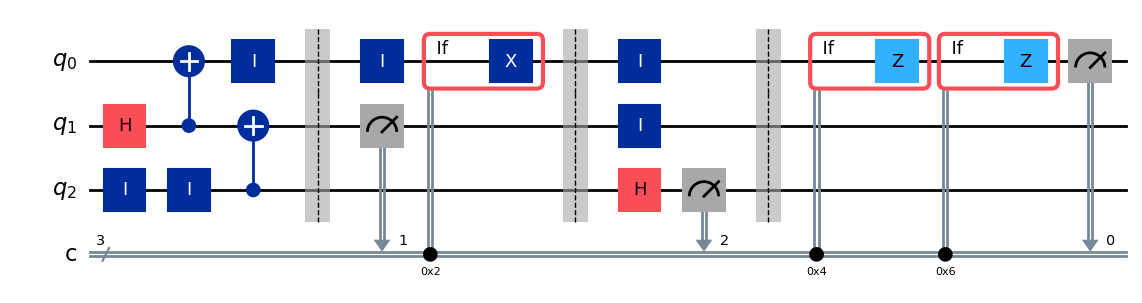

Figure 2 with |psi> = |0>  (bit string c2 c1 c0)
  000:   251 / 1024
  001:     0 / 1024
  010:   263 / 1024
  011:     0 / 1024
  100:   253 / 1024
  101:     0 / 1024
  110:   257 / 1024
  111:     0 / 1024
Problem 5a  --  Bob's bit c0 is always 0 ? True
Figure 2 with |psi> = |1>  (bit string c2 c1 c0)
  000:     0 / 1024
  001:   251 / 1024
  010:     0 / 1024
  011:   263 / 1024
  100:     0 / 1024
  101:   253 / 1024
  110:     0 / 1024
  111:   257 / 1024
Problem 5a  --  Bob's bit c0 is always 1 ? True


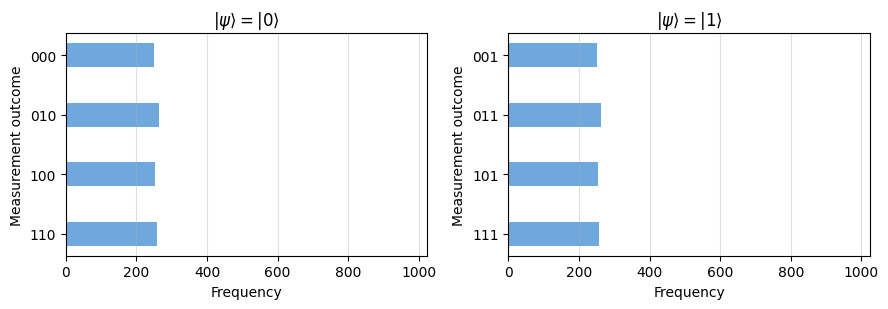

In [7]:
# --- Problem 5: the full teleportation circuit of Figure 2 (q2 = Alice, q1 = ancillary BB, q0 = Bob) ---
def figure2(psi_is_1, bit_1b=1, bit_3=0, x_when=2, z_when=(4, 6)):
    """Figure 2. bit_1b / bit_3: classical bits for the Step 1b / Step 3 measurements;
    x_when / z_when: register values that trigger Bob's conditional X / Z gates."""
    c  = ClassicalRegister(3, "c")
    qc = QuantumCircuit(QuantumRegister(3, "q"), c)
    if psi_is_1:
        qc.x(2)                          # the inset of Figure 3: |psi> = |1>
    # Step 1a
    qc.h(1)
    qc.id(2)
    qc.cx(1, 0)
    qc.id(2)
    qc.cx(2, 1)
    qc.id(0)
    qc.barrier()
    # Step 1b
    qc.id(0)
    qc.measure(1, bit_1b)
    with qc.if_test((c, x_when)):
        qc.x(0)
    qc.barrier()
    # Step 2
    qc.id([0, 1])
    qc.h(2)
    qc.measure(2, 2)
    qc.barrier()
    # Step 3
    for v in z_when:
        with qc.if_test((c, v)):
            qc.z(0)
    qc.measure(0, bit_3)
    return qc


display(figure2(psi_is_1=False).draw("mpl", fold=-1))
plt.close("all")


def side_by_side(cnts, titles, filename):
    """Figure 3 style: one horizontal histogram per input state."""
    fig, axes = plt.subplots(1, len(cnts), figsize=(9, 3.2))
    for ax, cnt, title in zip(axes, cnts, titles):
        keys = sorted(cnt, reverse=True)
        ax.barh(keys, [cnt[k] for k in keys], color="#6fa8dc", height=0.4)
        ax.set_xlim(0, SHOTS)
        ax.set_xlabel("Frequency")
        ax.set_ylabel("Measurement outcome")
        ax.set_title(title)
        ax.grid(axis="x", alpha=0.4)
    fig.tight_layout()
    fig.savefig(f"../images/{filename}", dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)


fig2_counts = [counts(figure2(psi_is_1=p)) for p in (False, True)]
for p, cnt in zip((0, 1), fig2_counts):
    report(cnt, f"Figure 2 with |psi> = |{p}>  (bit string c2 c1 c0)", 3)
    print(f"Problem 5a  --  Bob's bit c0 is always {p} ?", all(k[-1] == str(p) for k in cnt))
side_by_side(fig2_counts, [r"$|\psi\rangle = |0\rangle$", r"$|\psi\rangle = |1\rangle$"], "problem-5a-answer.png")

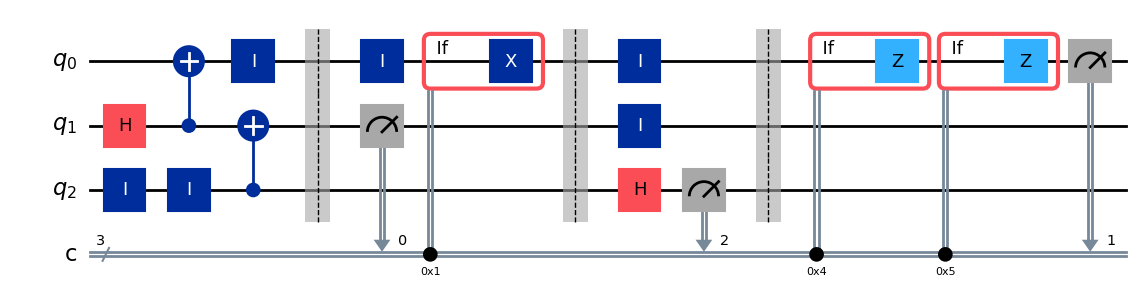

Modified Figure 2 with |psi> = |0>  (bit string c2 c1 c0)
  000:   251 / 1024
  001:   263 / 1024
  010:     0 / 1024
  011:     0 / 1024
  100:   253 / 1024
  101:   257 / 1024
  110:     0 / 1024
  111:     0 / 1024
Problem 5b  --  Bob's bit c1 is always 0 ? True
Modified Figure 2 with |psi> = |1>  (bit string c2 c1 c0)
  000:     0 / 1024
  001:     0 / 1024
  010:   251 / 1024
  011:   263 / 1024
  100:     0 / 1024
  101:     0 / 1024
  110:   253 / 1024
  111:   257 / 1024
Problem 5b  --  Bob's bit c1 is always 1 ? True


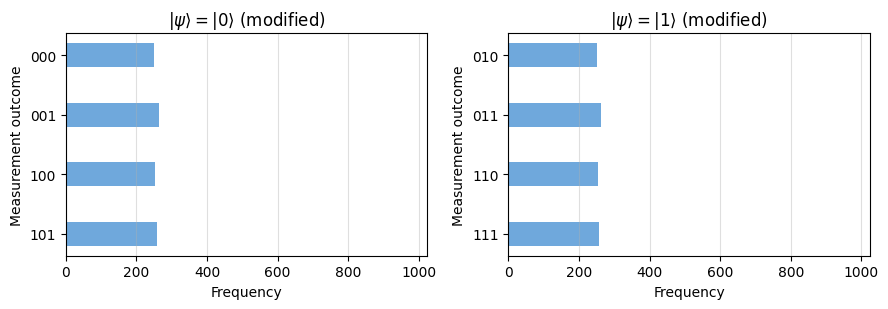

Problem 5b  --  identical to 5a after relabelling c0 <-> c1 ? True
---------------
Bits moved but conditions NOT updated, |psi> = |1>
  000:     0 / 1024
  001:   263 / 1024
  010:   251 / 1024
  011:     0 / 1024
  100:     0 / 1024
  101:   257 / 1024
  110:   253 / 1024
  111:     0 / 1024


In [8]:
# --- Problem 5b: Step 1b -> c0, Step 3 -> c1; conditions move to c == 1 (X) and c == 4, 5 (Z) ---
mod = dict(bit_1b=0, bit_3=1, x_when=1, z_when=(4, 5))
display(figure2(psi_is_1=False, **mod).draw("mpl", fold=-1))
plt.close("all")

mod_counts = [counts(figure2(psi_is_1=p, **mod)) for p in (False, True)]
for p, cnt in zip((0, 1), mod_counts):
    report(cnt, f"Modified Figure 2 with |psi> = |{p}>  (bit string c2 c1 c0)", 3)
    print(f"Problem 5b  --  Bob's bit c1 is always {p} ?", all(k[1] == str(p) for k in cnt))
side_by_side(mod_counts, [r"$|\psi\rangle = |0\rangle$ (modified)", r"$|\psi\rangle = |1\rangle$ (modified)"],
             "problem-5b-answer.png")

# the same outcomes once c0 and c1 are swapped back
swap01 = lambda cnt: {k[0] + k[2] + k[1]: v for k, v in cnt.items()}
print("Problem 5b  --  identical to 5a after relabelling c0 <-> c1 ?",
      all(swap01(m) == o for m, o in zip(mod_counts, fig2_counts)))

print("---------------")

# keeping the old conditions (x_when=2, z_when=(4, 6)) breaks the teleportation of |1>
broken = counts(figure2(psi_is_1=True, bit_1b=0, bit_3=1))
report(broken, "Bits moved but conditions NOT updated, |psi> = |1>", 3)

In [9]:
# --- Problem 5 (extra): both versions teleport a general state, not just |0> and |1> ---
def teleports(theta, phi, **kw):
    """Prepare Ry(theta) Rz(phi)|0> on Alice, teleport, undo the preparation on Bob: Bob must read 0."""
    qc = figure2(psi_is_1=False, **kw)
    prep = QuantumCircuit(3)
    prep.ry(theta, 2)
    prep.rz(phi, 2)
    qc = qc.compose(prep, front=True)
    # undo the preparation on Bob just before his measurement (the last instruction)
    last = qc.data.pop()
    qc.rz(-phi, 0)
    qc.ry(-theta, 0)
    qc.append(last)
    return counts(qc)


rng = np.random.default_rng(2110515)
for theta, phi in rng.uniform(0, np.pi, size=(3, 2)):
    for name, kw in (("Figure 2", {}), ("modified", mod)):
        bob = kw.get("bit_3", 0)   # Bob's classical bit; bit strings read c2 c1 c0
        ok = all(k[2 - bob] == "0" for k in teleports(theta, phi, **kw))
        print(f"Problem 5  --  theta={theta:.3f}, phi={phi:.3f}, {name:9s}: Bob always gets back |0> ? {ok}")

Problem 5  --  theta=1.762, phi=0.164, Figure 2 : Bob always gets back |0> ? True
Problem 5  --  theta=1.762, phi=0.164, modified : Bob always gets back |0> ? True
Problem 5  --  theta=1.451, phi=2.587, Figure 2 : Bob always gets back |0> ? True
Problem 5  --  theta=1.451, phi=2.587, modified : Bob always gets back |0> ? True
Problem 5  --  theta=2.765, phi=0.654, Figure 2 : Bob always gets back |0> ? True
Problem 5  --  theta=2.765, phi=0.654, modified : Bob always gets back |0> ? True


---

## **6. Quantum Teleportation vs. Hypothetical Teleportation**

In [10]:
# --- Problem 6: after Step 2 Alice's qubit is |0> or |1> -- the amplitudes alpha, beta are gone from her side ---
theta = 1.0
psi = np.array([np.cos(theta / 2), np.sin(theta / 2)])   # an "unknown" state alpha|0> + beta|1>
qc = QuantumCircuit(2)
qc.initialize(psi, 1)
qc.cx(1, 0)
qc.h(1)
sv = Statevector(qc)
for a in (0, 1):
    # project Alice (q1) onto |a>; Bob's conditional state, Z-corrected when a = 1
    bob = np.array([sv.data[2 * a + 0], sv.data[2 * a + 1]])
    bob = bob / np.linalg.norm(bob)
    if a == 1:
        bob = Z @ bob
    print(f"Problem 6  --  Alice reads {a}: Alice holds |{a}>, Bob (after correction) holds psi ? {np.allclose(bob, psi)}")

Problem 6  --  Alice reads 0: Alice holds |0>, Bob (after correction) holds psi ? True
Problem 6  --  Alice reads 1: Alice holds |1>, Bob (after correction) holds psi ? True


---

## **7. Other Forms of f(x)**

In [11]:
# --- Problem 7: U_f |x>|y> = |x>|y xor f(x)> for the four one-bit functions ---
def basis(bits):
    v = np.zeros(2 ** len(bits))
    v[int(bits, 2)] = 1
    return v


def U_f(f):
    """Oracle matrix whose column |x y> is |x, y xor f(x)>."""
    return np.column_stack([basis(f"{x}{y ^ f(x)}") for x in (0, 1) for y in (0, 1)])


FUNCS = {"A": lambda x: 0, "B": lambda x: x, "C": lambda x: 1 - x, "D": lambda x: 1}
EXPECTED = {"A": np.eye(4), "B": CNOT, "C": np.kron(X, I2) @ CNOT @ np.kron(X, I2), "D": np.kron(I2, X)}

for name, f in FUNCS.items():
    print(f"f_{name}:  f(0) = {f(0)}, f(1) = {f(1)}")
    for x in (0, 1):
        for y in (0, 1):
            print(f"  U_f |{x}>|{y}> = |{x}>|{y} xor {f(x)}> = |{x}>|{y ^ f(x)}>")
    display(Math(rf"U_{{f_{name}}} = " + latex_matrix(U_f(f))))
    print(f"Problem 7  --  U_f_{name} matches I / CNOT / anti-CNOT / I(x)X ?", np.allclose(U_f(f), EXPECTED[name]))
    print("---------------")

f_A:  f(0) = 0, f(1) = 0
  U_f |0>|0> = |0>|0 xor 0> = |0>|0>
  U_f |0>|1> = |0>|1 xor 0> = |0>|1>
  U_f |1>|0> = |1>|0 xor 0> = |1>|0>
  U_f |1>|1> = |1>|1 xor 0> = |1>|1>


<IPython.core.display.Math object>

Problem 7  --  U_f_A matches I / CNOT / anti-CNOT / I(x)X ? True
---------------
f_B:  f(0) = 0, f(1) = 1
  U_f |0>|0> = |0>|0 xor 0> = |0>|0>
  U_f |0>|1> = |0>|1 xor 0> = |0>|1>
  U_f |1>|0> = |1>|0 xor 1> = |1>|1>
  U_f |1>|1> = |1>|1 xor 1> = |1>|0>


<IPython.core.display.Math object>

Problem 7  --  U_f_B matches I / CNOT / anti-CNOT / I(x)X ? True
---------------
f_C:  f(0) = 1, f(1) = 0
  U_f |0>|0> = |0>|0 xor 1> = |0>|1>
  U_f |0>|1> = |0>|1 xor 1> = |0>|0>
  U_f |1>|0> = |1>|0 xor 0> = |1>|0>
  U_f |1>|1> = |1>|1 xor 0> = |1>|1>


<IPython.core.display.Math object>

Problem 7  --  U_f_C matches I / CNOT / anti-CNOT / I(x)X ? True
---------------
f_D:  f(0) = 1, f(1) = 1
  U_f |0>|0> = |0>|0 xor 1> = |0>|1>
  U_f |0>|1> = |0>|1 xor 1> = |0>|0>
  U_f |1>|0> = |1>|0 xor 1> = |1>|1>
  U_f |1>|1> = |1>|1 xor 1> = |1>|0>


<IPython.core.display.Math object>

Problem 7  --  U_f_D matches I / CNOT / anti-CNOT / I(x)X ? True
---------------


---

## **8. Creation of Superposition**

In [12]:
# --- Problem 8: (H H)(I X)|0>|0> = (H H)|0>|1> = |+>|-> ---
IX, HH = np.kron(I2, X), np.kron(H, H)
step1 = IX @ basis("00")
step2 = HH @ step1
display(Math(r"I \otimes X = " + latex_matrix(IX) + r",\quad H \otimes H = " + latex_matrix(HH)))
display(Math(r"(I \otimes X)\ket{00} = " + latex_matrix(step1.reshape(1, -1))
             + r",\quad (H \otimes H)\ket{01} = " + latex_matrix(step2.reshape(1, -1))))
display(Math(r"(H \otimes H)(I \otimes X) = " + latex_matrix(HH @ IX)))
print("Problem 8  --  (I X)|00> == |01> ?", np.allclose(step1, basis("01")))
print("Problem 8  --  (H H)|01> == |+>|-> ?", np.allclose(step2, np.kron(plus, minus)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Problem 8  --  (I X)|00> == |01> ? True
Problem 8  --  (H H)|01> == |+>|-> ? True


---

## **9. Hadamard Gate Applied to 2-Qubit Basis State**

In [13]:
# --- Problem 9: H^{(x)2}|01> from the formula 1/2^{n/2} sum_x (-1)^{x.y} |x> ---
n, y = 2, 0b01
dot = lambda x, y: bin(x & y).count("1") % 2   # bitwise inner product mod 2
formula = np.array([(-1) ** dot(x, y) for x in range(2 ** n)]) / 2 ** (n / 2)
for x in range(2 ** n):
    print(f"  x = {x:02b}:  x.y = {dot(x, y)},  sign {(-1) ** dot(x, y):+d}")
display(Math(r"H^{\otimes 2}\ket{01} = " + latex_matrix(formula.reshape(1, -1))))
print("Problem 9  --  formula == |+>|-> ?", np.allclose(formula, np.kron(plus, minus)))
print("Problem 9  --  formula == (H H)|01> (matrix, Problem 8) ?", np.allclose(formula, HH @ basis("01")))

  x = 00:  x.y = 0,  sign +1
  x = 01:  x.y = 1,  sign -1
  x = 10:  x.y = 0,  sign +1
  x = 11:  x.y = 1,  sign -1


<IPython.core.display.Math object>

Problem 9  --  formula == |+>|-> ? True
Problem 9  --  formula == (H H)|01> (matrix, Problem 8) ? True


---

## **10. Non-Constant Function in the Deutsch Algorithm**

In [14]:
# --- Problem 10: the balanced f_B(x) = x in the Deutsch algorithm ---
U_B = U_f(FUNCS["B"])
after_oracle = U_B @ np.kron(plus, minus)
display(Math(r"U_{f_B}\ket{+}\ket{-} = " + latex_matrix(after_oracle.reshape(1, -1))))
print("Problem 10  --  U_f|+>|-> == |->|-> ?", np.allclose(after_oracle, np.kron(minus, minus)))
final = np.kron(H, I2) @ after_oracle
print("Problem 10  --  after H on the MSB: |1>|-> ?", np.allclose(final, np.kron(ket1, minus)))

print("---------------")


def deutsch(name):
    """Figure 4 (IBM-Q convention: q1 = x = MSB, q0 = y = LSB), oracle built from gates."""
    qc = QuantumCircuit(2, 1)
    qc.x(0)
    qc.h([0, 1])
    qc.barrier()
    if name == "B":
        qc.cx(1, 0)
    elif name == "C":
        qc.x(1); qc.cx(1, 0); qc.x(1)
    elif name == "D":
        qc.x(0)
    qc.barrier()
    qc.h(1)
    qc.measure(1, 0)
    return qc


for name in FUNCS:
    print(f"Problem 10  --  f_{name}: MSB measured = {counts(deutsch(name))}")

<IPython.core.display.Math object>

Problem 10  --  U_f|+>|-> == |->|-> ? True
Problem 10  --  after H on the MSB: |1>|-> ? True
---------------
Problem 10  --  f_A: MSB measured = {'0': 1024}
Problem 10  --  f_B: MSB measured = {'1': 1024}
Problem 10  --  f_C: MSB measured = {'1': 1024}
Problem 10  --  f_D: MSB measured = {'0': 1024}
